# Phase II: Data Collection and Exploratory Data Analysis
##### INFO2950 Project by: Anderson Ramirez (ar2527) and Jackson Rhamy (jtr84)
##### GitHub Repository: [View Project Repository](https://github.com/RamirezDevOps/info2950_data_project)

### Research Question:

- What is the relationship between **Joe Biden’s presidential approval rating and how often he is mentioned** in political podcast episodes published from February 2021 through December 2024?
    - Subquestion: Does the relationship between Biden’s **approval rating** and **his mention rate** vary by **podcast political leaning**, particularly between conservative and liberal podcasts?
    - Subquestion: Did the frequency of Biden mentions in political podcasts **decline over the time** of his presidency, **regardless of countervailing changes in his approval rating**? 

#### Package Imports

We will import Python libraries to manipulate and visualize our data.

In [1]:
import pandas as pd
import numpy as np
import duckdb

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

### Data Collection and Cleaning

#### President Biden's Approval Ratings

The Where and What of this dataset:
- **Gallup Presidential Approval Ratings: Joe Biden**, provided by Gallup.
- The dataset can be downloaded as a CSV from the following link: https://news.gallup.com/poll/329384/presidential-approval-ratings-joe-biden.aspx

Why this dataset:
- This dataset provides information about Joe Biden’s presidential approval rating over time, allowing us to examine how his approval fluctuated during his presidency and **compare those changes with the frequency of his mentions in political podcasts**.

##### Loading President Biden's Approval Ratings CSV Data

Here we are loading the data, printing its shape and DataFrame.

In [2]:
# Load the CSV file containing Biden's approval ratings into a Pandas DataFrame
biden_ratings_df = pd.read_csv("bidenApprovalRating.csv")

print(f"The shape of biden_ratings_df is {biden_ratings_df.shape}")

biden_ratings_df.head()

The shape of biden_ratings_df is (56, 4)


,X.1,Approve,Disapprove,No opinion
0,NaN,%,%,%
1,<b>2025</b>,NaN,NaN,NaN
2,2025 Jan 2-15,40,54,6
3,<b>2024</b>,NaN,NaN,NaN
4,2024 Dec 2-18,39,56,5


##### Remove Headers, Unnecessary Columns, Rename Columns, and Convert Values

From the printed DataFrame, we can see that some rows have NaN values. These rows serve as headers that organize the data. For example, the first row specifies the units, in this case percentages, for the corresponding columns, while `<b>2025</b>` is a heading for the data collected in 2025.

Since these rows only provide additional information about the data rather than actual observations, we will **remove the rows with NaNs**. We will also **remove the `Disapprove` and `No opinion` columns** because our research questions focus on the approval rating specifically. 

Next, we will rename the columns to make their labels more descriptive, and **convert the percentage columns from an object to numeric data types** to make sure they can be used for analysis. Since these values represent percentages, **we will divide them by 100 to express them as a proportion** between 0 and 1. This way the dataset will only have relevant observations with clear variable names and appropriate data types.

In [3]:
# Remove any rows with missing data and reset the row numbers to start from 0
biden_ratings_df = biden_ratings_df.dropna().reset_index(drop=True)

# Drop the columns we don't need
biden_ratings_df = biden_ratings_df.drop(columns=['Disapprove', 'No opinion'])

# Rename the columns to clearer names
biden_ratings_df = biden_ratings_df.rename(columns={'X.1':'Date', 'Approve':'Approval_Proportion'})

# Ensure the approval column is treated as decimal numbers
biden_ratings_df = biden_ratings_df.astype({'Approval_Proportion':float})

# Convert the approval percentages into true proportions
biden_ratings_df['Approval_Proportion'] = biden_ratings_df['Approval_Proportion'] / 100

biden_ratings_df.head()

,Date,Approval_Proportion
0,2025 Jan 2-15,0.40
1,2024 Dec 2-18,0.39
2,2024 Nov 6-20,0.37
3,2024 Oct 14-27,0.41
4,2024 Oct 1-12,0.39


In [4]:
# Creating intermediate saving point.
biden_ratings_df.to_csv('bidenApprovalRatingClean.csv', index=False)

##### Format the Date column

From the original printed DataFrame, we see that the dates are not consistently formatted, some months have duplicate observations, and two polling periods span multiple months. For example, October 2024 has two observations of .41 and .39, while all dates have polling ranges, like 2024 Oct 14-27, rather than standard monthly dates like 2024-10. Additionally, two polling periods cross month boundaries, 2022 Nov 9-Dec 2 and 2021 Jan 21-Feb 2.

- The first date issue we will tackle is the polling periods that span two months. To handle these cases, we will **assign each polling observation to the month containing the midpoint of its polling period**. This is consistent with the methodology explained by political scientists Will Jennings and Christopher Wlezien in a 2013 paper, where they use the midpoint between a survey's fieldwork start and end dates to find its associated date (see References section for more information). Rather than arbitrarily assigning a survey to its start or end date, this method uses the midpoint of the actual data collection period.
    - While assigning polling observations to their corresponding months using the midpoint of each polling period,   we found that December 2022 had no approval observation. To keep a consistent monthly time series, we **added a row for December 2022 with a missing approval proportion (`NaN`)**. We chose to **preserve this missing value rather than estimate or interpolate it** because doing so would introduce an approval proportion that was not directly observed in our original dataset. This approach follows the time-series data cleaning practices discussed in Lecture 7, which emphasize maintaining consistent time intervals, explicitly representing missing observations, and documenting how missing data is handled.

As a result, our cleaned dataset contains **47 monthly observations, of which 46 have recorded approval proportions**. Analyses requiring approval proportions will use the 46 nonmissing observations.
- Next, we will address the presence of multiple observations within the same month. To resolve this, we will **convert the Date column object type to a Datetime type**, and then find the **average approval rating for each month**, that has multiple observations, using temporal aggregation, which combines higher frequency observations into a lower frequency, monthly dataset. **Each poll is weighted equally** regardless of its sample size or methodology; see our limitations section for more information. We chose this approach because our goal is to obtain one approval value per month for comparison with our podcast data, rather than develop a more sophisticated polling model.

- Finally, we are **removing January 2021 and January 2025** from our data because Joe Biden was not president for the full month in either case. Since he took office on January 20, 2021, and left on January 20, 2025, these two months only offer a few days of data instead of a complete 30 or 31 days. Because our research compares monthly presidential approval ratings against monthly podcast mentions, every data point needs to look at an identical timeframe. Keeping these partial months could skew the results and make the comparison unfair. Removing them leaves us with **47 complete, consistent months running from February 2021 through December 2024**.

In [5]:
# Loading intermediate data
biden_ratings_df = pd.read_csv('bidenApprovalRatingClean.csv')

# Replace specific cross-month date ranges with representative single dates for consistency
biden_ratings_df['Date'] = biden_ratings_df['Date'].replace({'2021 Jan 21-Feb 2':'2021 Jan 27', '2022 Nov 9-Dec 2':'2022 Nov 20'})

# Add a missing December 2022 observation with a NaN approval proportion
biden_ratings_df = pd.concat([biden_ratings_df, pd.DataFrame({'Date': ['2022 Dec 20'], 'Approval_Proportion':[np.nan]})], ignore_index=True)

# Convert dates to datetime format and standardize them to the first day of each month
biden_ratings_df['Date'] = pd.to_datetime(biden_ratings_df['Date'].str.split('-').str[0]).dt.to_period('M').dt.to_timestamp()

# Group observations by month and calculate the average approval proportion
# Sort the results chronologically by date
biden_ratings_df = duckdb.sql('SELECT Date, AVG("Approval_Proportion") AS "Approval_Proportion", \
                                            FROM biden_ratings_df GROUP BY Date ORDER BY Date').df()

# Exclude partial months
biden_ratings_df = biden_ratings_df[biden_ratings_df['Date'].between('2021-02-01', '2024-12-01')].reset_index(drop=True)

biden_ratings_df.head()

,Date,Approval_Proportion
0,2021-02-01,0.56
1,2021-03-01,0.54
2,2021-04-01,0.57
3,2021-05-01,0.54
4,2021-06-01,0.56


In [6]:
# Saving biden_ratings_df to a csv
biden_ratings_df.to_csv('bidenApprovalRatingClean.csv', index=False)

#### Political Podcast Data

The Where and What of this dataset:
- The dataset comes from the **Brookings Institution’s Popular Political Podcast Dataset**, which provides downloadable CSV data.
- It contains metadata for episodes of popular political podcasts, including **show names, publication dates, titles, descriptions, and assigned political leanings**.

Why this dataset:
- We use this dataset to **measure how frequently Joe Biden is mentioned** in political podcast episode metadata over time and **examine how mention rates vary by political leaning**, allowing us to compare these patterns with his presidential approval ratings.

##### Loading Political Podcast Data

Before cleaning our podcast dataset, we need to examine its structure to understand what information is available and find any potential issues that could affect our analysis. We will start by inspecting the dimensions, columns names, data types, and a sample of observations. This way we can see which columns are relevant and what cleaning steps are needed.

In [7]:
# Load the full podcast dataset from a CSV
podcasts_df = pd.read_csv("podcast_full-dataset.csv")

print(f"The shape of podcasts_df is {podcasts_df.shape}")

# Display column names, data types, and non-null counts
print(podcasts_df.info())

podcasts_df.head()

The shape of podcasts_df is (94855, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94855 entries, 0 to 94854
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         94855 non-null  int64 
 1   Episode ID         94855 non-null  int64 
 2   Show Name          94855 non-null  object
 3   Full Date          94855 non-null  object
 4   Title              94855 non-null  object
 5   Description        94831 non-null  object
 6   Partisan Leaning   94855 non-null  object
 7   Category on Apple  94855 non-null  object
 8   Entered Dataset    94855 non-null  object
 9   Audio URL          94852 non-null  object
dtypes: int64(2), object(8)
memory usage: 7.2+ MB
None


,Unnamed: 0,Episode ID,Show Name,Full Date,Title,Description,Partisan Leaning,Category on Apple,Entered Dataset,Audio URL
0,1,1,#SistersInLaw,2025-11-08,261: the earl of sandwich,jill wine-banks hosts #sistersinlaw to discuss...,More Liberal,News,Apple Recommendation,https://pdst.fm/e/arttrk.com/p/ABMA5/clrtpod.c...
1,2,2,#SistersInLaw,2025-11-01,"260: oh, snap",kimberly atkins stohr hosts #sistersinlaw to a...,More Liberal,News,Apple Recommendation,https://pdst.fm/e/arttrk.com/p/ABMA5/clrtpod.c...
2,3,3,#SistersInLaw,2025-10-25,"259: finally, an episode with sports",barb mcquade hosts #sistersinlaw to break down...,More Liberal,News,Apple Recommendation,https://pdst.fm/e/arttrk.com/p/ABMA5/clrtpod.c...
3,4,4,#SistersInLaw,2025-10-18,258: indictments for everyone,kimberly atkins stohr hosts #sistersinlaw to r...,More Liberal,News,Apple Recommendation,https://pdst.fm/e/arttrk.com/p/ABMA5/clrtpod.c...
4,5,5,#SistersInLaw,2025-10-11,257: unitary executive meets textualism,joyce vance hosts #sistersinlaw to analyze the...,More Liberal,News,Apple Recommendation,https://pdst.fm/e/arttrk.com/p/ABMA5/clrtpod.c...


##### Removing Unnecessary Columns and Handling Missing values

From the initial inspection, we found that multiple columns are not necessary for answering our research questions. Since our analysis focuses on the frequency of Biden mentions in podcast metadata, we will **only keep `Show Name`, `Full Date`, `Title`, `Description`, and `Partisan Leaning`**. The remaining columns will be dropped because they do not contribute to our analysis.

We also saw that the **`Description` column is missing 24 values**. Instead of removing these 24 episodes, we will **replace these values with empty strings**. This way we can **keep the observations and still find mentions of Biden via the episode titles**, even if they have a missing description.

In [8]:
# Remove unnecessary columns from the podcast dataset
podcasts_df = podcasts_df.drop(columns=['Episode ID', 'Unnamed: 0', 'Category on Apple', 'Entered Dataset', 'Audio URL'])

# Replace missing descriptions with empty strings
podcasts_df['Description'] = podcasts_df['Description'].fillna('')

print(f"The shape of podcasts_df is {podcasts_df.shape}")

# Check for remaining missing values in each column
print(f"Missing values after cleaning: \n{podcasts_df.isna().sum()}")

# Creating intermediate saving point.
podcasts_df.to_csv('podcastDataCleaned.csv', index=False)

podcasts_df.head()

The shape of podcasts_df is (94855, 5)
Missing values after cleaning: 
Show Name           0
Full Date           0
Title               0
Description         0
Partisan Leaning    0
dtype: int64


,Show Name,Full Date,Title,Description,Partisan Leaning
0,#SistersInLaw,2025-11-08,261: the earl of sandwich,jill wine-banks hosts #sistersinlaw to discuss...,More Liberal
1,#SistersInLaw,2025-11-01,"260: oh, snap",kimberly atkins stohr hosts #sistersinlaw to a...,More Liberal
2,#SistersInLaw,2025-10-25,"259: finally, an episode with sports",barb mcquade hosts #sistersinlaw to break down...,More Liberal
3,#SistersInLaw,2025-10-18,258: indictments for everyone,kimberly atkins stohr hosts #sistersinlaw to r...,More Liberal
4,#SistersInLaw,2025-10-11,257: unitary executive meets textualism,joyce vance hosts #sistersinlaw to analyze the...,More Liberal


##### Find Duplicates

We want to check if the dataset has any duplicate episodes. **Duplicate observations can affect our results** by causing certain episodes to be counted more than once, potentially inflating Biden's mentions.

We will check for **completely identical rows**, and then if any episodes share the **same `Show Name`, `Full Date`, and `Title`**, as this combination might show duplicate episodes.

In [9]:
print(f"Duplicate rows: {podcasts_df.duplicated().sum()}")

print(f"Potential duplicate episodes: {podcasts_df.duplicated(subset=['Show Name', 'Full Date', 'Title']).sum()}")

Duplicate rows: 144
Potential duplicate episodes: 192


The check found **144 completely identical rows** and **192 potential duplicated episodes** based on matching `Show Name`, `Full Date`, and `Title`. It is very possible that some episodes appear multiple times in the dataset. However, since the number of completely identical rows is lower, we will **investigate these observations more before removing them**.

In [10]:
# Find duplicate podcast episodes based on show name, date, and title
# Keep all occurrences of duplicates for inspection
duplicate_episodes = podcasts_df[podcasts_df.duplicated(subset=['Show Name', 'Full Date', 'Title'], keep=False)]

# Sort duplicate episodes by show name, date, and title
duplicate_episodes = duplicate_episodes.sort_values(by=['Show Name', 'Full Date', 'Title'])

duplicate_episodes.head(10)

,Show Name,Full Date,Title,Description,Partisan Leaning
2937,Bannon's War Room,2023-11-29,episode 3208: massive protest and unrest in ir...,episode 3208: massive protest and unrest in ir...,More Conservative
2938,Bannon's War Room,2023-11-29,episode 3208: massive protest and unrest in ir...,episode 3208: massive protest and unrest in ir...,More Conservative
1365,Bannon's War Room,2025-05-01,episode 4453: creating legislation to stop the...,episode 4453: creating legislation&nbsp;to sto...,More Conservative
1366,Bannon's War Room,2025-05-01,episode 4453: creating legislation to stop the...,episode 4453: creating legislation&nbsp;to sto...,More Conservative
9150,Bill O'Reilly's No Spin News and Analysis,2020-05-05,"the o'reilly update, may 5, 2020",the nation’s biggest supermarket chains begin ...,More Conservative
9151,Bill O'Reilly's No Spin News and Analysis,2020-05-05,"the o'reilly update, may 5, 2020","another day, another joe biden gaffe...learn m...",More Conservative
8939,Bill O'Reilly's No Spin News and Analysis,2020-08-19,"the o'reilly update, august 19, 2020","stocks recover losses caused by the contagion,...",More Conservative
8940,Bill O'Reilly's No Spin News and Analysis,2020-08-19,"the o'reilly update, august 19, 2020",undecided voters in america...learn more about...,More Conservative
8406,Bill O'Reilly's No Spin News and Analysis,2021-06-11,"o'reilly update morning edition, june 11, 2021","on this friday edition of the o'reilly update,...",More Conservative
8407,Bill O'Reilly's No Spin News and Analysis,2021-06-11,"o'reilly update morning edition, june 11, 2021","what is ""whiteness""...learn more about your ad...",More Conservative


##### Removing Duplicate Episodes

After seeing the potentially duplicated observations, we found that some episodes are **completely identical across all five columns**, while others share the **same show, publication date, and the title but had different descriptions**.

Since descriptions are important to finding Biden mentions, we decided to **only remove the 144 identical rows**. We **keep the 48 episodes with different descriptions** because they might represent different content, even if it shares the same title and date.

In [11]:
# Remove duplicate rows and reset the DataFrame index
podcasts_df = podcasts_df.drop_duplicates().reset_index(drop=True)

# Check the number of remaining duplicate rows
print(f"Remaining duplicate rows: {podcasts_df.duplicated().sum()}")

print(f"The shape of podcasts_df now is {podcasts_df.shape}")

Remaining duplicate rows: 0
The shape of podcasts_df now is (94711, 5)


##### Filtering Episodes to Biden's Presidency 

Because our research focuses on podcast episodes published during Biden's presidency, we will filter `podcasts_df` to include only episodes published from **February 1, 2021, through December 31, 2024**. This keeps our podcast data **aligned with the 47 complete months** isolated for our analysis.

In the initial inspection, we saw that `Full Date` is stored as an object rather than a datetime data type. Thus, we will **convert this column into a Pandas datetime object** to conduct some chronological filtering.

We will then filter `podcasts_df` directly to **keep only episodes published during Biden's presidency**, rather than making a separate DataFrame. Episodes outside this time frame will be excluded because they are not relevant to our research questions. We will also reset the index of the filtered DataFrame so that observations are numbered consecutively. 

Finally, we will compare the dimensions of the dataset before and after filtering and make sure the publication dates match our desired time frame.

In [12]:
# Convert the 'Full Date' column to datetime format
podcasts_df['Full Date'] = pd.to_datetime(podcasts_df['Full Date'])

# Store the original dataset shape before filtering
og_shape = podcasts_df.shape

# Filter episodes to include only those published from February 01, 2021, through December 31, 2024
podcasts_df = podcasts_df[podcasts_df['Full Date'].between('2021-02-01', '2024-12-31')]

# Reset the DataFrame index after filtering
podcasts_df = podcasts_df.reset_index(drop=True)

# Display the original and filtered dataset dimensions
print(f"Original dataset shape: {og_shape}")
print(f"Filtered dataset shape: {podcasts_df.shape}")

# Check the earliest and latest publication dates in the filtered dataset
print(f"Earliest date: {podcasts_df['Full Date'].min()}")
print(f"Latest date: {podcasts_df['Full Date'].max()}")

# Creating intermediate saving point.
podcasts_df.to_csv('podcastDataCleaned.csv', index=False)

podcasts_df.head()

Original dataset shape: (94711, 5)
Filtered dataset shape: (56042, 5)
Earliest date: 2021-02-01 00:00:00
Latest date: 2024-12-31 00:00:00


,Show Name,Full Date,Title,Description,Partisan Leaning
0,#SistersInLaw,2024-12-28,216: super yacht rock,joyce vance hosts #sistersinlaw to review the ...,More Liberal
1,#SistersInLaw,2024-12-21,215: minnie mouse would do a better job,barb mcquade hosts #sistersinlaw to discuss fa...,More Liberal
2,#SistersInLaw,2024-12-14,214: misprision,jill wine-banks hosts #sistersinlaw to discuss...,More Liberal
3,#SistersInLaw,2024-12-07,213: pardon me,kimberly atkins stohr hosts #sistersinlaw to e...,More Liberal
4,#SistersInLaw,2024-11-30,212: keep calm and carry on,joyce vance hosts #sistersinlaw to investigate...,More Liberal


##### Find Biden Mentions in Podcast Metadata

To find which podcast episodes mention Biden, we will parse through the Title and Description columns using Pandas `str.contains()` method. 

First, we will check each column separately for the word "Biden," with **case-insensitive matching to account for differences in capitalization and a regular expression to match the entire word**. Because Hunter Biden was a massive presence in the general news cycle due to this criminal trial and legal troubles, his media coverage could skew our data. To make sure this does not happen, we will explicitly **exclude any mentions of Hunter Biden** in our count.

Finally, we will combine the remaining results from both columns to create a binary variable called `Biden_mention`, where **1 means Biden is in the title or description and 0 indicates he is not**. **Episodes where Biden is mentioned in both columns will only be counted once**.

In [13]:
# Find all mentions of "Biden"
title_biden = podcasts_df['Title'].str.contains(r"\bBiden\b", case=False, na=False)
description_biden = podcasts_df['Description'].str.contains(r"\bBiden\b", case=False, na=False)

# Combine them 
podcasts_df['Biden_mention'] = (title_biden + description_biden).astype(int)

# Find rows that mention "Hunter Biden"
has_hunter_title = podcasts_df['Title'].str.contains("Hunter Biden", case=False, na=False)
has_hunter_desc = podcasts_df['Description'].str.contains("Hunter Biden", case=False, na=False)

# If "Hunter Biden" is in the title OR description, set 'Biden_mention' back to 0
podcasts_df.loc[has_hunter_title | has_hunter_desc, 'Biden_mention'] = 0

print(podcasts_df["Biden_mention"].value_counts())

podcasts_df[["Title", "Description", "Biden_mention"]].head()

Biden_mention
0    43584
1    12458
Name: count, dtype: int64


,Title,Description,Biden_mention
0,216: super yacht rock,joyce vance hosts #sistersinlaw to review the ...,1
1,215: minnie mouse would do a better job,barb mcquade hosts #sistersinlaw to discuss fa...,0
2,214: misprision,jill wine-banks hosts #sistersinlaw to discuss...,1
3,213: pardon me,kimberly atkins stohr hosts #sistersinlaw to e...,1
4,212: keep calm and carry on,joyce vance hosts #sistersinlaw to investigate...,0


##### Grouping Episodes by Month

To find the relationship between Biden's monthly approval rating and his mention frequency in political podcasts, we will organize the dataset by month.

We will create a `Month` column using the `Full Date` column to identify the year and month each episode was published. Then, we will **group the episodes by month** and calculate the **total number of episodes published and the number of episodes mentioning Biden**. These values will help us calculate the **monthly Biden mention rate as the proportion of episodes mentioning Biden out of all episodes published that month**. These results will be stored in a separate DataFrame called `monthly_podcasts_df` while preserving the original episode data.

In [14]:
# Extract the year and month from each episode's publication date
podcasts_df["Month"] = podcasts_df["Full Date"].dt.to_period("M")

# Group episodes by month and calculate the total number of episodes and Biden mentions
monthly_podcasts_df = podcasts_df.groupby("Month").agg(
    Total_episodes=("Biden_mention", "count"),
    Biden_episodes=("Biden_mention", "sum")
).reset_index()

# Calculate the monthly proportion of episodes mentioning Biden
monthly_podcasts_df["Mention_Proportion"] = (monthly_podcasts_df["Biden_episodes"] / monthly_podcasts_df["Total_episodes"])

# Creating intermediate saving point.
podcasts_df.to_csv('podcastDataCleaned.csv', index=False)
monthly_podcasts_df.to_csv('monthlyPodcastData.csv', index=False)

monthly_podcasts_df.head()

,Month,Total_episodes,Biden_episodes,Mention_Proportion
0,2021-02,688,158,0.229651
1,2021-03,802,240,0.299252
2,2021-04,777,187,0.240669
3,2021-05,740,154,0.208108
4,2021-06,789,181,0.229404


##### Inspect Political Leaning Column

We need to **verify that our Partisan Leaning column is consistent** because one of our research questions examines whether the relationship between Biden's approval rating and podcast mention frequency differs by political leaning.

We will see unique values in this column and **count the number of observations belonging to each classification**.

In [15]:
print(podcasts_df["Partisan Leaning"].unique())
print(podcasts_df["Partisan Leaning"].value_counts())

print(f"Missing values: {podcasts_df["Partisan Leaning"].isna().sum()}")

['More Liberal' 'More Conservative' 'Moderate' 'Unknown']
Partisan Leaning
More Conservative    33918
More Liberal         12865
Unknown               5362
Moderate              3897
Name: count, dtype: int64
Missing values: 0


The `Partisan Leaning` column has **four categories, `More Liberal`, `More Conservative`, `Moderate`, and `Unknown`**. There are **no missing values**, so no additional cleaning is necessary. We will **keep the `Unknown` category to preserve all observations, but exclude it when comparing political leanings**.

### Combined Monthly Dataset

The Where and What of this dataset:
- This is a derived dataset created by **merging Gallup’s Biden presidential approval ratings with monthly statistics from the Brookings political podcast dataset**, producing **47 monthly observations and nine columns covering February 2021 through December 2024**.

Why this dataset:
- We created this dataset to examine the **relationship between Biden’s monthly presidential approval ratings and the proportion of political podcast episodes mentioning him**, including **how this relationship varies across liberal, moderate, and conservative podcasts**.

##### Prepare the Datasets for Merging

Before merging the two datasets, we need to make sure the month columns use the same format and that their measurements are consistent.

In `biden_ratings_df`, the `Date` column represents the first day of each month, `Approval_Proportion` is already expressed as a proportion between 0 and 1. In `monthly_podcasts_df`, `Month` is stored as a monthly period, while `Mention_Proportion` is expressed as a decimal, ranging from 0 to 1.

We will make copies of both datasets to keep our previous cleaning work. Then, we will **rename and convert the date columns into a common `Month` format**. We will also **recalculate the podcast mention rate as a proportion** using the number of episodes that mention Biden divided by the total number of episodes.

Finally, we will conduct a **sanity check for duplicate months in either dataset**, since each month should only have one observation before we merge the data.

In [16]:
# Load Datasets
approval_monthly = pd.read_csv('bidenApprovalRatingClean.csv')
podcast_monthly = pd.read_csv('monthlyPodcastData.csv')

# Renames the approval date column and standardizes both month columns to the first day of each month.
approval_monthly = approval_monthly.rename(columns={"Date": "Month"})

approval_monthly['Month'] = pd.to_datetime(approval_monthly['Month']).dt.to_period('M').dt.to_timestamp()

podcast_monthly['Month'] = pd.to_datetime(podcast_monthly['Month'].astype(str)).dt.to_period('M').dt.to_timestamp()

# Recalculate the podcast mention proportion from counts
podcast_monthly["Mention_Proportion"] = podcast_monthly["Biden_episodes"] / podcast_monthly["Total_episodes"]

# Keep only columns needed
approval_monthly = approval_monthly[["Month", "Approval_Proportion"]]
podcast_monthly = podcast_monthly[["Month", "Total_episodes", "Biden_episodes", "Mention_Proportion"]]

# Verify there is one row per month
print(f"Duplicate approval months: {approval_monthly["Month"].duplicated().sum()}")
print(f"Duplicate podcast months: {podcast_monthly["Month"].duplicated().sum()}")

print(approval_monthly.head())
print(podcast_monthly.head())

Duplicate approval months: 0
Duplicate podcast months: 0
       Month  Approval_Proportion
0 2021-02-01                 0.56
1 2021-03-01                 0.54
2 2021-04-01                 0.57
3 2021-05-01                 0.54
4 2021-06-01                 0.56
       Month  Total_episodes  Biden_episodes  Mention_Proportion
0 2021-02-01             688             158            0.229651
1 2021-03-01             802             240            0.299252
2 2021-04-01             777             187            0.240669
3 2021-05-01             740             154            0.208108
4 2021-06-01             789             181            0.229404


##### Merging the Datasets

Now that both datasets have been standardized, we can combine them using the Month column. We will use a **left join with the podcast dataset as the primary table** to **keep all months with podcast observations, even if the corresponding approval proportions are missing**.

The combined dataset will contain the monthly approval proportion, total podcast episodes, episodes mentioning Biden, and the proportion of episodes mentioning Biden.

To address our subquestion about political leaning, we will also use our cleaned episode-level podcast data to **calculate monthly Biden mention proportions for conservative, moderate, and liberal podcasts**. These proportions will be added as separate columns to our combined dataset, allowing us to compare political leanings while **keeping one observation per month**.

Additionally, we will create a new variable that measures the monthly difference in Biden mention proportions between liberal and conservative podcasts. We will calculate this by **subtracting the conservative mention proportion from the liberal mention proportion (Liberal_Proportion - Conservative_Proportion)**. A **positive value indicates that liberal podcasts mentioned Biden more frequently, while a negative value indicates that conservative podcasts mentioned him more frequently**. This will allow us to examine how the difference in mention proportions between the two political leanings changes over time and relates to Biden's approval proportion.

After merging, we will **check for missing values** to identify months without approval ratings or podcast information. We will also **verify that the previously identified missing approval proportion for December 2022 remains** in the combined dataset.

In [17]:
# Merge monthly podcast data with approval ratings.
combined_monthly_df = duckdb.sql('SELECT p.Month, p.Total_episodes, p.Biden_episodes, p.Mention_Proportion, \
                                        a.Approval_Proportion FROM podcast_monthly AS p LEFT JOIN \
                                        approval_monthly AS a ON p.Month = a.Month ORDER BY p.Month').df()

# Loading the cleaned episode level podcast dataset
podcasts_leaning = pd.read_csv("podcastDataCleaned.csv")

# Standardize the Month column
podcasts_leaning["Month"] = pd.to_datetime(podcasts_leaning["Month"]).dt.to_period("M").dt.to_timestamp()

# Group episodes by month and political leaning
leaning_monthly = podcasts_leaning.groupby(["Month", "Partisan Leaning"]).agg(
    Total_episodes=("Biden_mention", "count"),
    Biden_episodes=("Biden_mention", "sum")
).reset_index()

# Calculate mention proportions for each political leaning
leaning_monthly["Mention_Proportion"] = leaning_monthly["Biden_episodes"] / leaning_monthly["Total_episodes"]

# Turn political leaning categories into separate columns
leaning_wide = leaning_monthly.pivot(index="Month", columns="Partisan Leaning", values="Mention_Proportion").reset_index()

# rename the political leaning columns
leaning_wide = leaning_wide.rename(columns={
    "More Conservative": "Conservative_Mention",
    "Moderate": "Moderate_Mention",
    "More Liberal": "Liberal_Mention",
    "Unknown": "Unknown_Mention"
})

# Add political leaning mention proportions to the combined data
combined_monthly_df = combined_monthly_df.merge(leaning_wide, on='Month', how='left')

# Calculate the monthly difference between liberal and conservative mentions
combined_monthly_df["Liberal_Conservative_Difference"] = combined_monthly_df["Liberal_Mention"] - combined_monthly_df["Conservative_Mention"]

# Check the shape of merged dataset
print(f"Combined dataset shape: {combined_monthly_df.shape}")

# Check for missing values and display them
print(combined_monthly_df.isna().sum())
print(combined_monthly_df[combined_monthly_df.isna().any(axis=1)])

combined_monthly_df.head()

Combined dataset shape: (47, 10)
Month                              0
Total_episodes                     0
Biden_episodes                     0
Mention_Proportion                 0
Approval_Proportion                1
Moderate_Mention                   0
Conservative_Mention               0
Liberal_Mention                    0
Unknown_Mention                    0
Liberal_Conservative_Difference    0
dtype: int64
        Month  Total_episodes  Biden_episodes  Mention_Proportion  \
22 2022-12-01            1146             144            0.125654   

    Approval_Proportion  Moderate_Mention  Conservative_Mention  \
22                  NaN          0.126761              0.170306   

    Liberal_Mention  Unknown_Mention  Liberal_Conservative_Difference  
22         0.051471         0.034483                        -0.118835  


,Month,Total_episodes,Biden_episodes,Mention_Proportion,Approval_Proportion,Moderate_Mention,Conservative_Mention,Liberal_Mention,Unknown_Mention,Liberal_Conservative_Difference
0,2021-02-01,688,158,0.229651,0.56,0.142857,0.283951,0.197802,0.050000,-0.086148
1,2021-03-01,802,240,0.299252,0.54,0.136364,0.382353,0.192308,0.156250,-0.190045
2,2021-04-01,777,187,0.240669,0.57,0.136364,0.320186,0.174107,0.070000,-0.146078
3,2021-05-01,740,154,0.208108,0.54,0.100000,0.268409,0.138614,0.113402,-0.129795
4,2021-06-01,789,181,0.229404,0.56,0.081081,0.281879,0.190244,0.130000,-0.091635


In [18]:
# Creating intermediate saving point.
combined_monthly_df.to_csv('combinedMonthlyProportions.csv', index=False)

### Data Description



#### "Gallup Presidential Approval Ratings: Joe Biden" Dataset

**- What are the observations (rows) and the attributes (columns)?**

**The cleaned Gallup dataset has 47 monthly observations from February 2021 until December 2024.** Each row is one month in Joe Biden's presidency and records his approval proportion for the month. The attributes (columns) are 

*Date*: Standardized to be the **first day of the month in which the observation corresponds**.
*Approval_proportion*: Biden's **presidential approval rating for said month expressed as a proportion** between 0 and 1 as opposed to a percentage.

**- Why was this dataset created?**

**This dataset was used to track changes in Biden's presidential approval over time** and examine if those changes were associated with the frequency with which he was mentioned in political podcast metadata (to see how this is achieved, see below.)

**- How did you create this dataset? What tools, procedures, and data sources did you use?**

We downloaded Gallup's presidential approval rating as a CSV file. **The main library of tools we used to clean and transform the data was Pandas**, which  helped us to convert the raw data into clean monthly observations that could be eventually combined with our podcast dataset. To achieve this, our procedure involved **selecting relevant approval rating information, converting dates and approval values into the consistent monthly and proportional formats, and grouping observations by month**. After doing this, we saved the cleaned data to use in our analysis and to merge with the podcast data.

**- What processes might have influenced what data was observed and recorded and what was not?**

The dataset is based on approval ratings collected and published by Gallup through surveys rather than measurements of the opinions of every American. As a result, approval ratings are estimates that may be affected by sampling variability and the timing of the polling period. **The CSV file we used did not include sample sizes or margins of error, which limits our ability to assess the precision of the monthly estimates. Additionally, aggregating observations by month can obscure changes in approval within a month, and averaging multiple observations gives each observation equal weight regardless of its sample size.**

**- What preprocessing was done, and how did the data come to be in the form that you are using?**

We **removed unnecessary rows and columns, standardized the dates, converted approval percentages into proportions, and averaged multiple observations that appeared in a single month**. For situations where the polling periods spanned across two months, we assigned the observation to the month containing the midpoint of the polling period. We **decided to retain December 2022 with the missing value to keep months sequential**. After doing, this we were able to preprocess our data and make it easily mergeable with podcast data.

**- If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?**

**We did not survey people ourselves.** What we did was **use an existing dataset** that collects public opinion. Gallup states that respondents know that their answers will be factored into their polls, but this data is not directly included in our dataset.

**- Where can your raw source data be found, if applicable? Provide a link to the raw data (hosted on Github, in a Cornell Google Drive or Cornell Box).**

Gallup presidential approval ratings — Joe Biden: https://news.gallup.com/poll/329384/presidential-approval-ratings-joe-biden.aspx

Raw CSV files used in our analysis: https://drive.google.com/drive/folders/1Qq1Ne2AHGYFrRtM5lEPPehE-ikWU0Dv6?usp=drive_link

#### Brookings Institution Podcast Dataset

**- What are the observations (rows) and the attributes (columns)?**

We cleaned the dataset then transformed it to aggregate podcast episodes by month. As such the **observations are individual months from February 2021 through December 2024**. Each of these rows summarizes the number of podcasts and proportion of podcasts mentioning Joe Biden in a month.

The attributes are the following:
*Month*: The month to which the observation corresponds.
*Total_episodes*: The total number of podcast episodes in the Brookings dataset published during that month.
*Biden_episodes*: The number of podcast episodes whose titles or descriptions mention Joe Biden during that month, excluding episodes identified as mentioning Hunter Biden.
*Mention_Proportion*: The proportion of podcast episodes published during that month that mention Joe Biden, calculated by dividing Biden_episodes by Total_episodes.

**- Why was this dataset created?**

This **dataset was created to investigate how the frequency of Joe Biden mentions in podcasts changed over the time of his presidency**. In aggregating podcast episode data by month, we will be able to combine the data with presidential approval rating to compare mention rate with public opinion of Joe Biden.

**- How did you create this dataset? What tools, procedures, and data sources did you use?**

The dataset was derived from the **Brookings Popular Political Podcast dataset** using **Python and Pandas as our tools**. **Our procedure for creating this dataset involved grouping episodes by month and counting the total number of episodes mentioning Biden.** We then calculated the monthly mention proportion by dividing the number of episodes mentioning Biden by the total number of episodes that month. This resulted in a dataset summarizing Biden mention rates in podcasts from February 2021 through December 2024.

**- What processes might have influenced what data was observed and recorded and what was not?**

A few processes may have influenced which episodes were counted. First, **we decided to rely entirely on the Brookings dataset, and since it only focuses on selected popular podcasts, were only able to record mention rates among popular political podcasts and not the whole podcast ecosystem**. After this, we also identified if Biden was mentioned in a podcast by searching podcast titles and descriptions for the word "Biden" while excluding all entries including mentions of "Hunter Biden". As a result, **episodes mentioning Biden without putting him in the title or description will be missed, while episodes mentioning a different person with the name Biden will be included (though this is quite rare)**. Further, episodes containing the phrase “Hunter Biden” in their titles or descriptions were excluded to reduce mentions of Biden referring to his son, although this could also exclude episodes discussing Joe Biden.

**- What preprocessing was done, and how did the data come to be in the form that you are using?**

We cleaned the original Brookings podcast dataset using Python and Pandas. **We removed five unnecessary columns, replaced missing episode descriptions with empty strings, and removed 144 completely duplicated rows.** We retained records sharing the same show name, publication date, and title when their descriptions differed, since the descriptions could contain distinct information.

After this, we converted publication dates to datetime format and restricted the data to episodes published from February 1, 2021, through December 31, 2024. We searched episode titles and descriptions for the word “Biden” and created a binary indicator identifying episodes with a match, and excluded records containing “Hunter Biden”. **We subsequently grouped the cleaned episode-level data by month, calculated the total number of episodes and number of episodes mentioning Biden, and divided the latter by the former to obtain the monthly mention proportion**. The resulting overall monthly aggregate contains 47 observations, one for each month from February 2021 through December 2024.

**- If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?**

**The dataset contains podcast episode metadata rather than information collected directly from survey participants**. Documentation does not confirm whether or not podcast hosts or producers were aware if their podcast metadata would be included in the Brookings Institution's analysis, but given that they are public-figures, it is likely that they know that their podcasts will be used to generate data analysis of some kind.

**- Where can your raw source data be found, if applicable? Provide a link to the raw data (hosted on Github, in a Cornell Google Drive or Cornell Box).**

Raw CSV files used in our analysis: https://drive.google.com/drive/folders/1Qq1Ne2AHGYFrRtM5lEPPehE-ikWU0Dv6?usp=drive_link

The raw data can also be downloaded from these sites:

Brookings political podcast data: 
https://politicalpodcastproject.shinyapps.io/dataset/

#### Combined Dataset

**- What are the observations (rows) and the attributes (columns)?**
The observations (rows) are individual months from February 2021 through December 2024, with each row summarizing podcast episode mentions of Joe Biden and his presidential approval rating for a given month. Each row summarizes the frequency of Joe Biden mentions in political podcast episode metadata and his presidential approval rating for that month. January 2021 and January 2025 were excluded because they represent incomplete months within the study period. Thus, the resulting dataset contains **47 monthly observations**.

The attributes (columns) are the following: 
*- Month*: The month to which the observation corresponds.
*- Total_episodes*: The total number of podcast episodes in the Brookings dataset for each month.
*- Biden_episodes*: The number of podcast episodes in the Brookings dataset that mention Biden in their metadata each month.
*- Mention_proportion*: The proportion of all podcast episodes in a given month that mention Biden, calculated by dividing Biden_episodes by Total_episodes.
*- Approval_proportion*: Joe Biden's presidential approval rating for each month, expressed as a proportion.
*- Moderate_Mention*: The proportion of podcast episodes labeled politically moderate that mention Biden in a given month.
*- Conservative_Mention*: The proportion of podcast episodes labeled politically conservative that mention Biden in a given month.
*- Liberal_Mention*: The proportion of podcast episodes labeled politically liberal that mention Biden in a given month.
*- Unknown_Mention*: The proportion of podcast episodes with an unknown political leaning that mention Biden in a given month.
*- Liberal_Conservative_Difference*: The difference in Biden mention proportions between Liberal and Conservative podcasts. A positive value indicates that liberal podcasts mentioned Biden more frequently, while a negative value indicates that conservative podcasts mentioned him more frequently.

**- Why was this dataset created?**

This dataset was created to investigate the relationship between Joe Biden's presidential approval rating and the frequency that he was mentioned in political podcast episodes during his presidency, from February 2021 until December 2024. We combined the Gallup presidential approval rating data with podcast data from the Brookings Institution to determine whether changes in Biden's public approval were at all associated with changes in how frequently he was mentioned in podcast metadata. Furthermore, the dataset lets us probe into how this relationship may have differed between liberal, moderate, and conservative podcasts, as well as whether Biden's mention rate declined over time independent of changes in approval rating.

**- How did you create this dataset? What tools, procedures, and data sources did you use?**

We created this dataset by **combining two data sources**: the "Gallup's Presidential Approval Ratings: Joe Biden" dataset and a Brookings Institution dataset containing information about episodes from the selected top political podcasts. The Gallup dataset gave us Biden's presidential approval ratings over time, while the Brookings dataset gave us access to podcast episode metadata, such as publication dates, titles, descriptions, and political leanings. We downloaded both datasets as CSV files and used the Python libraries Pandas, NumPy, and DuckDB to clean, process, and combine the data.

First of all, we cleaned the Gallup dataset by removing unnecessary rows and columns, converting approval rating percentages to proportions, and standardizing the dates for ease of analysis. When multiple observations appeared in a single month, we calculated the average to get a single monthly approval rating. When the polling period spanned across 2 months, we **assigned the observation to the month containing the midpoint of the polling period**. Because December of 2022 had no approval observation, we **preserved that month with a missing approval value instead of estimating one**.

After this, we cleaned the Brookings Institution podcast dataset by removing unneeded columns, replacing missing descriptions with empty strings, and **removing 144 completely duplicated rows**. We kept episodes that shared a show name, publication, and title but have differing descriptions, since they could have different and important information that would be otherwise lost. Subsequently, we filtered the dataset down to episodes published between February 2021 through December 2024 (the time Biden's presidency excluding the first and last month due to incomplete data). Using Pandas, we searched episode titles and descriptions for the word "Biden", without regard for capitalization, and **created a binary variable** that showed whether a given episode mentioned "Biden" in its metadata. To avoid mentions Joe Biden's son, we excluded all the selections containing the string "Hunter Biden".

To prepare the podcast dataset for merging with the approval rating dataset, we **grouped podcast episodes by month** and calculated the total amount of episodes published per month, number of episodes mentioning "Biden" per month, and from this got the proportion of Biden mentions per month. We repeated this process for the political leaning categories of liberal, moderate, conservative, and unknown.

After all of this cleaning and paring down of data, we were finally able to merge the two datasets. We merged the two using the month as the common identifier, and the resulting dataset has **47 monthly observations and 10 attributes**. From here, we will use Matplotlib and Seaborn to conduct exploratory data analysis.

**- What processes might have influenced what data was observed and recorded and what was not?**

There are a few processes inherited from the datasets we merged that may have influenced what data was observed and recorded and what was not. When we filtered the podcast data to include mentions of Joe Biden, we searched simply using the word "Biden". This means that episodes mentioning someone named Biden who is not president will be included, while **episodes that discuss him but do not mention him in the metadata will not be included**. Furthermore, for months that had multiple polling observations, we averaged the observations to get a single monthly rating. This **could obscure fluctuations in approval within a month**, and **each poll was weighted equally** regardless of its sample size. December 2022 had no available approval rating, so we preserved it as missing rather than estimating a value. Finally, we decided to deliberately exclude the January at the beginning of Biden's term and at the end. Including them would have resulted in observations that were only part of a month, and this is not directly comparable with complete months. Further, on a practical level, we noticed that their inclusion resulted in very fragile and skewed data being introduced into our analysis.

**- What preprocessing was done, and how did the data come to be in the form that you are using?**

For far more detail, please reference the "How did you create this dataset?" question. That said, we will list all the ways we manipulated our data:

The Gallup approval dataset was cleaned by removing unnecessary rows and columns, converting approval percentages into proportions, standardizing dates, and averaging multiple observations within each month. Polling periods spanning two months were assigned to the month containing their midpoint, and December 2022 was retained with a missing approval value rather than an estimated one. The Brookings podcast dataset was cleaned by removing unnecessary columns, replacing missing descriptions with empty strings, and removing 144 exact duplicate rows. We then filtered episodes to Biden’s presidency (February 2021 through December 2024) and used Pandas to identify mentions of “Biden” in episode titles and descriptions, regardless of capitalization and excluding "Hunter Biden". Finally, we aggregated episodes by month to calculate total episode counts, Biden mention counts, and mention proportions overall and by political leaning, then merged these monthly statistics with Gallup’s approval ratings by month to create the final dataset of 47 monthly observations and 10 attributes.

**- If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?**

This question is not applicable as the only thing we did to get this dataset was combine two CSVs. To see our commentary on how the two preexisting CSVs involved people, see above.

**- Where can your raw source data be found, if applicable? Provide a link to the raw data (hosted on Github, in a Cornell Google Drive or Cornell Box).**

Raw CSV files used in our analysis: https://drive.google.com/drive/folders/1Qq1Ne2AHGYFrRtM5lEPPehE-ikWU0Dv6?usp=drive_link

The raw data can also be downloaded from these sites:

Gallup presidential approval ratings - Joe Biden: 
https://news.gallup.com/poll/329384/presidential-approval-ratings-joe-biden.aspx
Brookings political podcast data: 
https://politicalpodcastproject.shinyapps.io/dataset/

### Data Limitations

There are a few limitations that may affect our findings.

First, our **podcast metadata does not track every mention of Joe Biden in an episode**. For example, an episode that discusses Biden extensively without mentioning his name in the description or title will not be counted. By contrast, a mention in the title or podcast description does not consequently necessitate that Biden be a major topic of discussion. Thus, the results we find will strictly be **a measure of Biden’s presence in podcast metadata and not the number of mentions in the audio**. This could affect the meaning of the results and how people interpret them because it could cause people to mistakenly interpret our results as measuring how much podcasts discuss Biden when they actually measure the proportion of episodes whose metadata mentions him.

Secondly, the data on podcasts derived from Brookings explicitly focuses on a **selection of the top political podcasts rather than the entire ecosystem of podcasts**. As a result, the included podcasts may not fully represent every single political podcast. This could affect the meaning of the results and how people interpret them because people could incorrectly generalize our findings to smaller podcasts and less popular shows. 

Third, the data for presidential approval ratings are derived from surveys rather than measurements of every American's opinion. The uploaded file does not include sample sizes or margins of sampling error. Further it has minimal missing data. As a result, the approval ratings may not perfectly represent public opinion, and the **lack of information about sampling uncertainty limits our ability to assess the precision of these estimates**. This could affect the meaning of the results and how people interpret them because people may not understand that approval ratings are estimates and not an exact value.

Fourth, to avoid counting episodes focused on Hunter Biden as mentions of Joe Biden, we excluded episodes containing the phrase "Hunter Biden" from our Biden mention count. However, this approach **may also exclude episodes that discuss both Hunter Biden and Joe Biden**, potentially underestimating the proportion of episodes mentioning Joe Biden. We chose this method to reduce false positives, but recognize that it may affect the meaning of the results and how people interpret them by introducing false negatives into our dataset.

Fifth, the **observational design of our project cannot establish causation**. Although the project examines the relationship between Biden's approval rating and his frequency of mentions in political podcasts, **both variables may be influenced by external factors**, such as major political events, elections, and controversies. Thus, the analysis may be able to show associations between approval ratings and podcast mentions but cannot establish whether changes in one variable cause changes in the other. Nonetheless, because our research question focuses on correlation rather than causation, this limitation does not prevent us from addressing our primary research question. Even so, this could affect the meaning of the results and how people interpret them because people have the potential to intrpret the association as evidence that one variable causes the other.

Lastly, labels defining category and **political ideology supplied by the Brookings Institution may simplify the actual views represented by a podcast**. These classifications will be treated as provisional, source-provided labels as opposed to perfect and nuanced measurements of a show’s political ideology. This could affect the meaning of the results and how people interpret them because people could interpret political labels as an exact distillation of a podcast's political beliefs when it is not.

How could this affect the meaning of results and the impact of results on people overall?

The answer is that these limitations could lead readers of our findings to **overgeneralize them, projecting them onto situations far broader than what we are analyzing**. Since our data measures mentions in podcast metadata over a relatively limited time period, and since our data only covers a selection of popular political podcasts, our results **may not accurately map onto how all podcasts discuss Biden or how podcasts discuss presidents in general**. Further, political categories assigned by the Brookings Institution are not definitive political identifiers, but to a reader of a study, it may be easy to interpret them as such.  What this all means is that our findings should be treated by readers as evidence derived from our dataset and **not necessarily final conclusions about the relationship between political podcasts and presidential approval rating**.

### Exploratory data analysis

#### President Biden's Approval Ratings

In [19]:
# Loading cleaned Data.
biden_ratings_df = pd.read_csv('bidenApprovalRatingClean.csv', parse_dates=['Date'])

##### Descriptive statistics

Here we are going to look at the descriptive statistics from the cleaned dataset to begin analyzing the data.

In [20]:
biden_ratings_df.describe()

,Date,Approval_Proportion
count,47,46.000000
mean,2022-12-31 09:42:07.659574528,0.422826
min,2021-02-01 00:00:00,0.360000
25%,2022-01-16 12:00:00,0.390000
50%,2023-01-01 00:00:00,0.410000
75%,2023-12-16 12:00:00,0.427500
max,2024-12-01 00:00:00,0.570000
std,NaN,0.053610


##### Findings

The cleaned Biden presidential approval dataset contains **47 monthly observations, of which 46 have recorded approval proportions** and **one has a missing value for December 2022**. Among the recorded observations, the **mean approval proportion was approximately 0.4228, while the median was 0.41**.

The approval ratings **ranged from .36 to a maximum of .57**, with a standard deviation of approximately 0.0536. The **middle 50% of monthly approval ratings fell between .39 and 0.4275**, showing that most observations were concentrated within a relatively small range. The mean being slightly bigger than the median shows that **some higher approval observations might have pulled the average upward**. 

The statistics give us an initial understanding of the distribution and variation in President Biden's monthly approval ratings; however, they do not show us how approval changed over time.

##### Monthly Approval Time Series

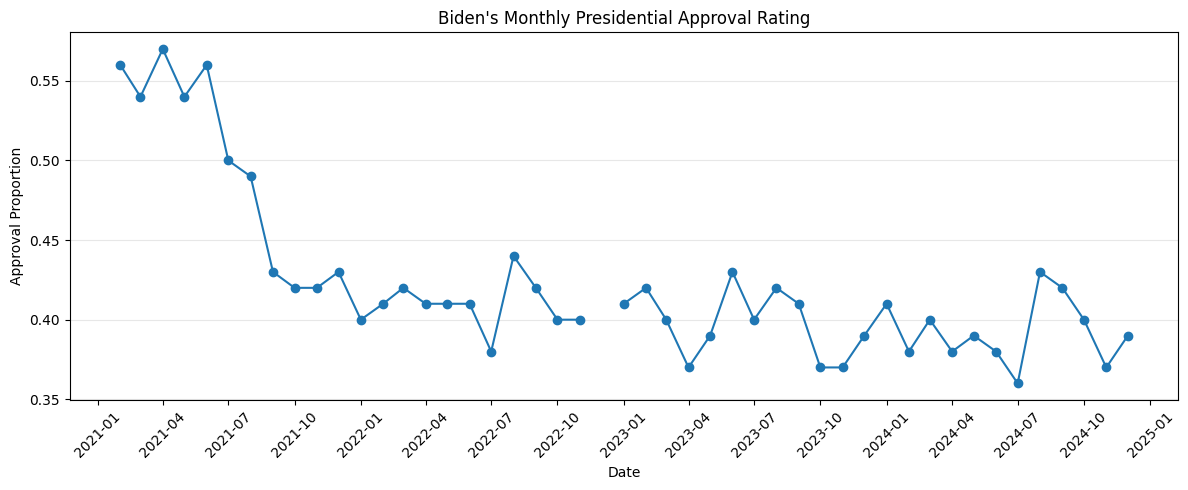

In [21]:
fig, time_series = plt.subplots(figsize=(12, 5))

time_series.plot(
    biden_ratings_df['Date'],
    biden_ratings_df['Approval_Proportion'],
    marker="o"
)

time_series.xaxis.set_major_locator(
    mdates.MonthLocator(bymonth=[1, 4, 7, 10])
)

time_series.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.xlabel('Date')
plt.ylabel('Approval Proportion')
plt.title("Biden's Monthly Presidential Approval Rating")
time_series.grid(axis='y', alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##### Monthly Presidential Approval Ratings Over Time Findings

The time-series plot shows Biden's monthly presidential approval proportions from February 2021 through December 2024. The graph shows a **substantial decline in approval during 2021, from approximately 0.56 in February to 0.43 by December**. After this decline, approval proportions **remained relatively stable but continued to fluctuate throughout the rest of his presidency**, generally ranging between 0.37 and 0.44. The **lowest observed monthly approval proportion occurred in July 2024, at 0.36**, followed by an increase to 0.43 in August 2024.

Overall, this visualization shows that Biden's approval proportions experienced a **substantial decline early in his presidency, followed by a prolonged period of lower approval** with some monthly fluctuations. It is also worth noting that **December 2022 contains a missing value, resulting in a gap in the time-series plot**. We chose to preserve this gap rather than estimate or interpolate the missing approval proportion, as doing so would introduce a value that was not directly observed in the original dataset.

##### Histogram of Monthly Approval Ratings


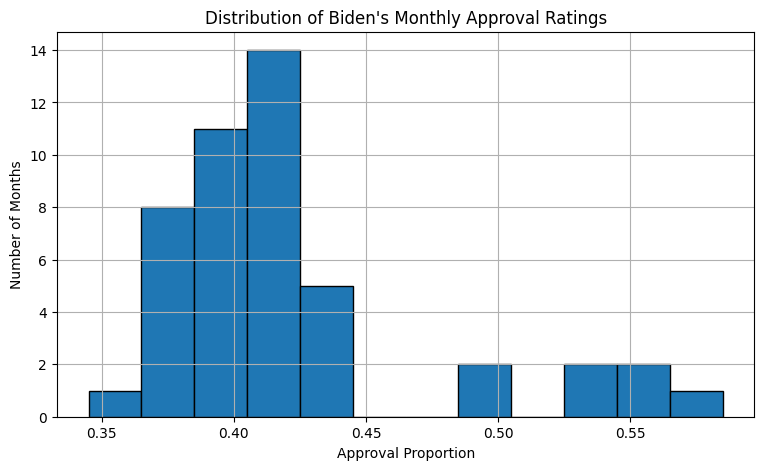

In [22]:
biden_ratings_df.hist(
    column='Approval_Proportion',
    bins=[0.345, 0.365, 0.385, 0.405, 0.425, 0.445, 0.465, 0.485, 0.505, 0.525, 0.545, 0.565, 0.585],
    edgecolor='black',
    figsize=(9, 5)
)

plt.xlabel("Approval Proportion")
plt.ylabel("Number of Months")
plt.title("Distribution of Biden's Monthly Approval Ratings")
plt.show()

##### Histogram of Monthly Approval Ratings Findings

The histogram shows that Biden's monthly approval proportions are concentrated in a relatively narrow range. Of the 46 months with recorded approval proportions, **39 fall between approximately 0.36 and 0.44**, with the **highest concentration around 0.40 to 0.42**. There is also a **smaller group of 7 months with approval proportions of approximately 0.49 or higher**, separated from the main cluster by a gap between roughly 0.45 and 0.48.

This makes the **distribution appear right-skewed**, with the **higher approval proportions pulling the mean (0.423) above the median (0.41)**. As seen in the time-series plot, these **higher approval proportions occurred during the earlier months of Biden's presidency in 2021**.

#### Political Podcast Data

##### Line Plot of Numbers of Podcast Episodes Published per Month

<Axes: title={'center': 'Total Podcast Episodes per Month'}, xlabel='Month', ylabel='Number of Episodes'>

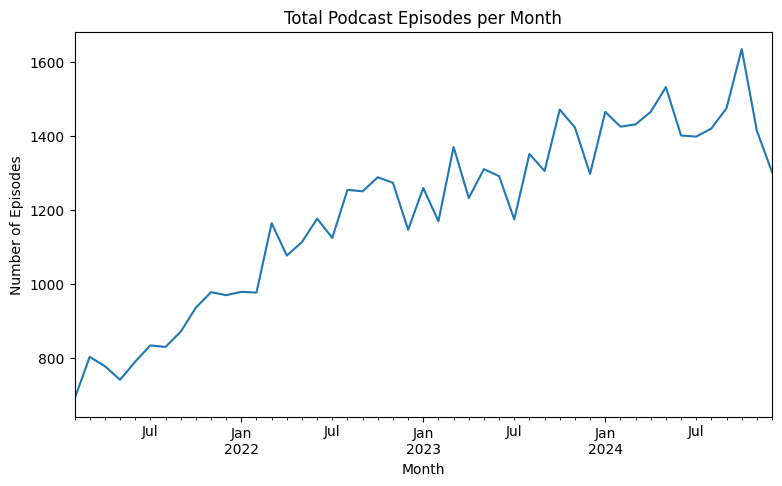

In [23]:
monthly_podcasts_df.plot(
    x='Month',
    y='Total_episodes',
    kind='line',
    title='Total Podcast Episodes per Month',
    xlabel='Month',
    ylabel='Number of Episodes',
    legend=False,
    figsize=(9, 5)
)

The line plot shows that the **total number of podcast episodes generally increased throughout the study period**, despite some monthly fluctuations. The number of episodes published varies across months, which may reflect differences in podcast publishing frequency and the coverage of shows in our dataset.

Because the **total number of episodes differs across months**, we **use the proportion of episodes mentioning Biden rather than the raw number of mentions**. This allows us to make **more consistent comparisons across months with different episode totals**.

##### Line Plot of Biden Mention Rate Over Time

<Axes: title={'center': 'Biden Mention Rate Over Time'}, xlabel='Month', ylabel='Proportion of Episodes Mentioning Biden'>

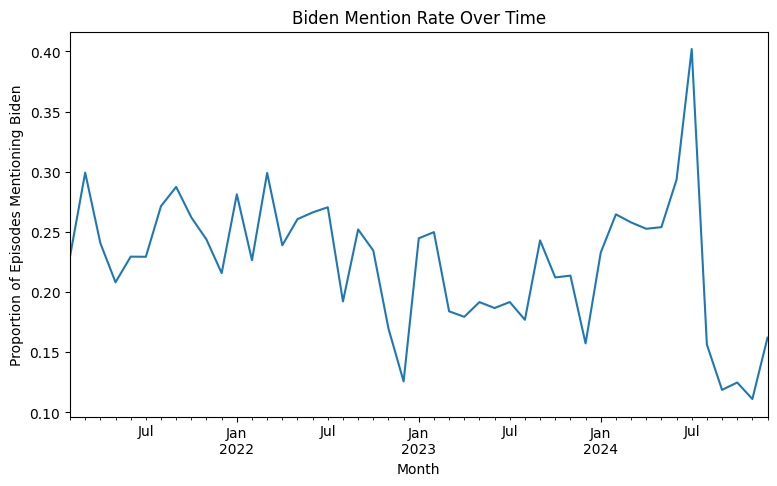

In [24]:
monthly_podcasts_df.plot(
    x='Month',
    y='Mention_Proportion',
    kind='line',
    title='Biden Mention Rate Over Time',
    xlabel='Month',
    ylabel='Proportion of Episodes Mentioning Biden',
    legend=False,
    figsize=(9, 5)
)

The line plot shows that the proportion of podcast episodes mentioning Biden **fluctuated throughout his presidency rather than consistently declining**. Mention proportions **generally ranged between 0.18 and 0.30** for much of the data, with occasional dips below this range. There was a noticeable increase in mid-2024, reaching a **peak of approximately 0.40 in July 2024**, followed by a **sharp decline to around 0.11–0.16 during the final months of 2024**.

The graph suggests that Biden's mention proportion declined toward the end of his presidency, but it **does not show a consistent downward trend across the entire study period**.

##### Episodes and Shows by Political Leaning

In [25]:
print(f"Episodes by Political Leaning: {podcasts_df['Partisan Leaning'].value_counts()}")

print(f"Shows by Political Leaning: \n{podcasts_df.groupby('Partisan Leaning')['Show Name'].nunique()}")

Episodes by Political Leaning: Partisan Leaning
More Conservative    33918
More Liberal         12865
Unknown               5362
Moderate              3897
Name: count, dtype: int64
Shows by Political Leaning: 
Partisan Leaning
Moderate              9
More Conservative    43
More Liberal         44
Unknown              12
Name: Show Name, dtype: int64


Conservatives and liberal podcasts have a **similar number of unique shows**, but **conservative podcasts account for more episodes (33,918 compared with 12,865)**. **Moderate podcasts are less represented, with only 9 shows and 3,897 episodes**.

##### Top 10 Podcasts by Episode Count

In [26]:
show_counts = podcasts_df.groupby('Show Name').size()
top_10_shows = show_counts.sort_values(ascending=False).head(10)
print(top_10_shows)

Show Name
The Clay Travis and Buck Sexton Show           6715
Bill O'Reilly's No Spin News and Analysis      3339
Bannon's War Room                              2682
The Glenn Beck Program                         2054
The MeidasTouch Podcast                        1536
The Great America Show with Lou Dobbs          1361
John Solomon Reports                           1308
Mark Levin Podcast                             1195
The Late Show Pod Show with Stephen Colbert    1101
The Rubin Report                               1036
dtype: int64


The results show that **some podcast shows contribute more episodes than others**. **The Clay Travis and Buck Sexton Show has the most episodes (6,715)**, followed by Bill O'Reilly's No Spin News and Analysis (3,339) and Bannon's War Room (2,682). A **small number of frequently publishing shows might have disproportionate influence on overall Biden's mention rates**, since **our analysis weights each episode equally**.

##### Biden Mention Rate by Political Leaning

In [27]:
mention_by_leaning = podcasts_df.groupby('Partisan Leaning')['Biden_mention'].mean()
print(mention_by_leaning)

Partisan Leaning
Moderate             0.301771
More Conservative    0.264402
More Liberal         0.138749
Unknown              0.098657
Name: Biden_mention, dtype: float64


The results show that **moderate podcasts have the highest Biden mention rate at .30**, followed by **conservative podcasts at .26 and liberal podcasts at .14**. Podcasts with an **unknown political leaning have the lowest mention rate at .10**.

##### Biden Mention Rate Over Time by Political Leaning

<Axes: title={'center': 'Biden Mention Rate Over Time by Political Leaning'}, xlabel='Month', ylabel='Proportion of Episodes Mentioning Biden'>

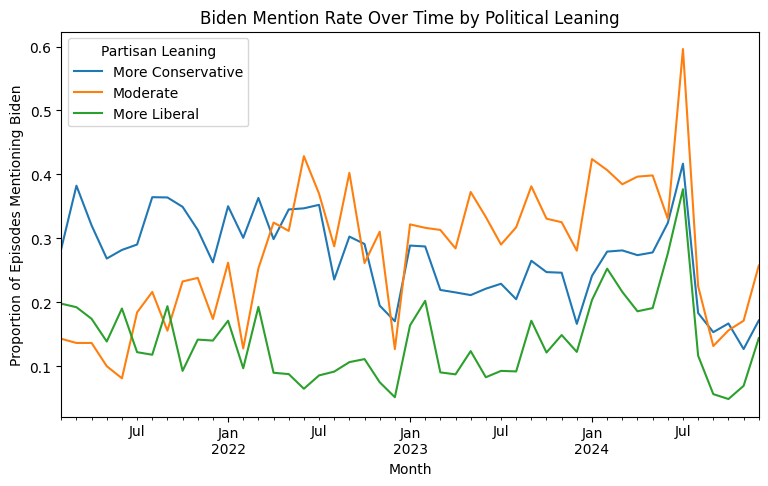

In [28]:
monthly_leaning = podcasts_df.groupby(["Month", "Partisan Leaning"])["Biden_mention"].mean().unstack()

monthly_leaning[["More Conservative", "Moderate", "More Liberal"]].plot(
    kind='line',
    title='Biden Mention Rate Over Time by Political Leaning',
    xlabel='Month',
    ylabel='Proportion of Episodes Mentioning Biden',
    figsize=(9, 5)
)

The line plot shows that **Biden's mention proportions varied across political leanings throughout his presidency**. **Moderate podcasts frequently had higher mention proportions** than the other groups, but their values also fluctuated considerably. Because the moderate category contains only 9 unique shows and substantially fewer episodes, these patterns may be **more sensitive to the behavior of individual podcasts**.

When comparing liberal and conservative podcasts, an interesting visual pattern emerges. At certain points, liberal and conservative podcasts show similar trends in their mention proportions of Joe Biden, such as around July 2024, when Biden withdrew from the presidential race. However, **conservative podcasts generally mention Biden more frequently than liberal podcasts**. Although there are some periods when liberal mention proportions decrease while conservative mention proportions increase, this **does not appear to be a consistent pattern across the study period**. In fact, the **positive correlation between the two groups suggests that their mention proportions tend to move in the same direction overall**. Nevertheless, the difference in mention proportions between liberal and conservative podcasts is worth investigating further through one of our proposed hypotheses (see below).

#### Combined Monthly Dataset

In [29]:
# Load combined monthly data
combined_monthly_df = pd.read_csv('combinedMonthlyProportions.csv', parse_dates=['Month'])

##### Presidential Approval Rating and Biden Mention Rate Over Time

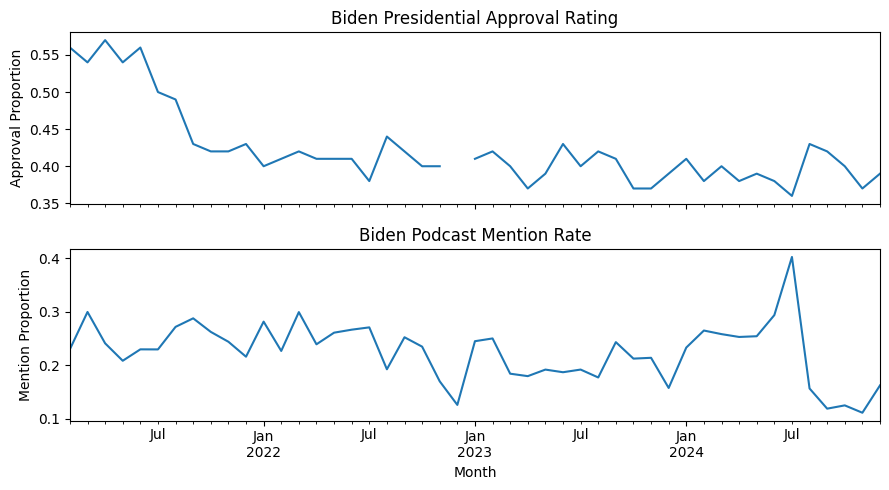

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Biden Approval Rating Plot
combined_monthly_df.plot(
    x='Month',
    y='Approval_Proportion',
    kind='line',
    ax=axes[0],
    title='Biden Presidential Approval Rating',
    ylabel='Approval Proportion',
    legend=False,
    figsize=(9, 5)
)

# Biden Podcast Mention Rate Plot
combined_monthly_df.plot(
    x='Month',
    y='Mention_Proportion',
    kind='line',
    ax=axes[1],
    title='Biden Podcast Mention Rate',
    ylabel='Mention Proportion',
    legend=False,
    figsize=(9, 5)
)

plt.tight_layout()
plt.show()

The plots show that Biden's **approval proportion declined substantially during the beginning of his presidency** before **remaining relatively stable around 0.40**, with some fluctuations. Meanwhile, his podcast mention proportion fluctuated throughout his presidency, including a **sharp increase in mid-2024 followed by a steep decline toward the end of 2024**.

The **two variables do not appear to follow similar patterns over time**. While approval proportions remained relatively stable after the initial decline, podcast mention proportions continued to fluctuate, suggesting that **changes in approval alone may not explain changes in podcast mentions**.

##### Relationship Between Approval Rating and Biden Mention Rate

We will distinguish the beginning of Biden's presidency (2021) from later years to see whether the relationship between approval ratings and mention rates differs across these periods.

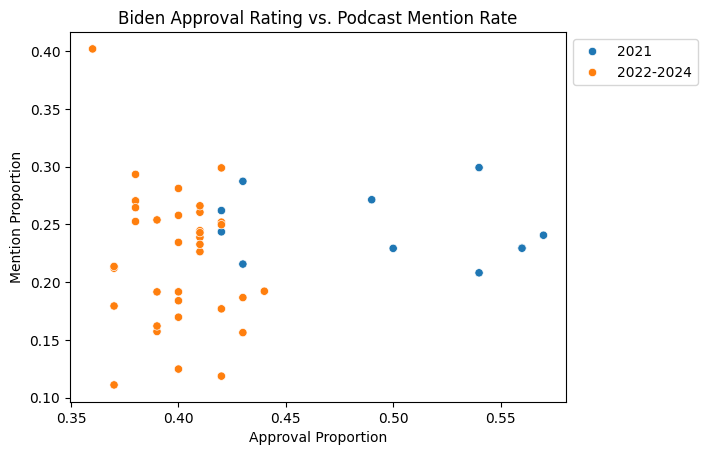

In [31]:
# Separate 2021 from later years
combined_monthly_df['Period'] = '2022-2024'

combined_monthly_df.loc[combined_monthly_df['Month'].dt.year == 2021, 'Period'] = '2021'

# Makes scatterplot
sns.scatterplot(
    data=combined_monthly_df,
    x='Approval_Proportion',
    y='Mention_Proportion',
    hue='Period'
)

plt.title('Biden Approval Rating vs. Podcast Mention Rate')
plt.xlabel('Approval Proportion')
plt.ylabel('Mention Proportion')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

The scatterplot shows **no clear relationship between Biden's approval proportion** and his overall podcast mention proportion. In 2021, approval proportions were generally higher, while mention proportions varied. From 2022 through 2024, **approval proportions were concentrated at lower values**, but podcast mention proportions continued to fluctuate considerably.

The wide variation in mention proportions at similar approval levels suggests that **Biden's approval proportion alone may not explain how frequently political podcasts mentioned him**.

##### Approval Rating vs. Biden Mention Rate by Political Leaning


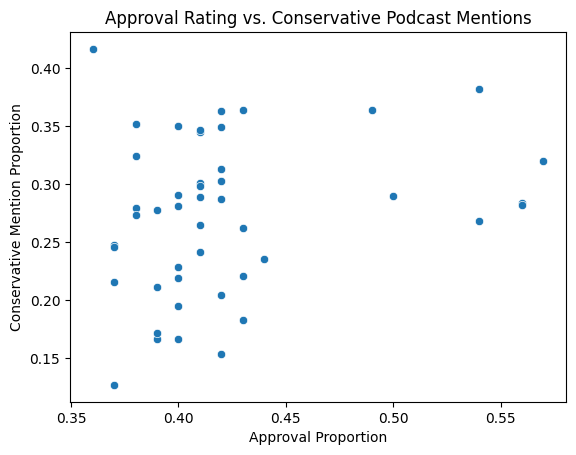

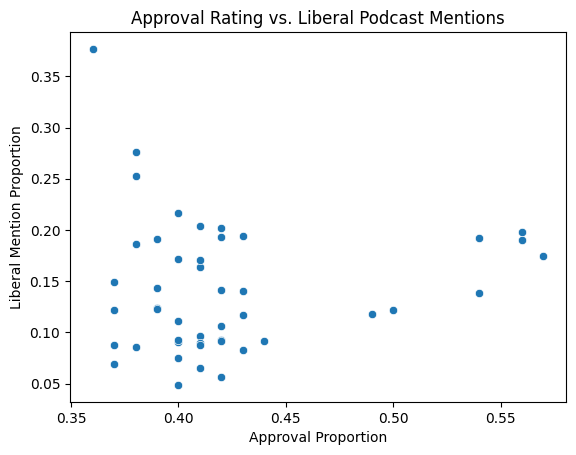

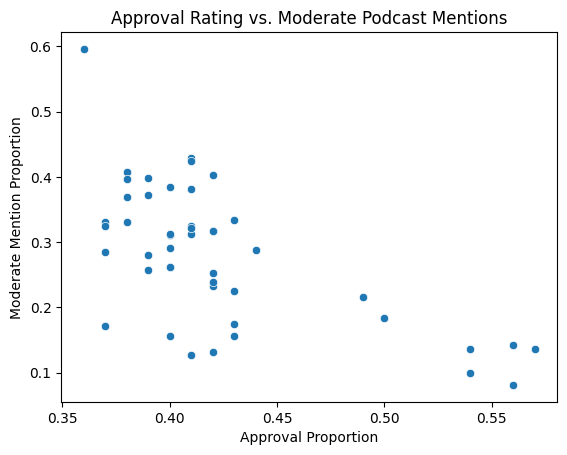

In [32]:
# Scatterplot for conservative podcasts
sns.scatterplot(
    data=combined_monthly_df,
    x='Approval_Proportion',
    y='Conservative_Mention'
)

plt.title('Approval Rating vs. Conservative Podcast Mentions')
plt.xlabel('Approval Proportion')
plt.ylabel('Conservative Mention Proportion')
plt.show()

# Scatterplot for liberal podcasts
sns.scatterplot(
    data=combined_monthly_df,
    x='Approval_Proportion',
    y='Liberal_Mention'
)

plt.title('Approval Rating vs. Liberal Podcast Mentions')
plt.xlabel('Approval Proportion')
plt.ylabel('Liberal Mention Proportion')
plt.show()

# Scatterplot for Moderate_Mention
sns.scatterplot(
    data=combined_monthly_df,
    x='Approval_Proportion',
    y='Moderate_Mention'
)

plt.title('Approval Rating vs. Moderate Podcast Mentions')
plt.xlabel('Approval Proportion')
plt.ylabel('Moderate Mention Proportion')
plt.show()

The scatterplots show **different relationships between Biden's approval proportion and podcast mention proportions across political leanings**. **Conservative podcasts show a weak positive relationship**, while **liberal podcasts show little apparent relationship**. **Conservative podcasts generally have higher mention proportions than liberal podcasts** across most approval levels.

In contrast, moderate podcasts **show a stronger negative relationship**, with mention proportions generally decreasing as Biden's approval proportion increases. However, this **finding should be interpreted with caution** because the moderate category contains only 9 unique shows and 3,897 episodes, compared with 43 conservative shows and 33,918 episodes and 44 liberal shows and 12,865 episodes. The **smaller number of moderate shows may make these results more sensitive to the coverage patterns of individual podcasts** and less representative of moderate political podcasts overall.

##### Correlation Between Approval Ratings and Mention Rates

We will **calculate both Pearson and Spearman correlations** to examine the relationship between Biden's monthly approval proportion and the proportion of political podcast episodes mentioning him. **Pearson correlation measures the strength and direction of a linear relationship** between two variables. **Spearman correlation measures the strength and direction of a monotonic relationship** using the ranks of observations rather than their actual values.

We will use **Pearson as our primary descriptive correlation** because we are interested in the linear relationship between approval and mention proportions. **Spearman will serve as an additional check** to determine whether the direction and strength of the relationship are similar when using ranks. Comparing both correlations will provide a more complete understanding of the relationship.

Additionally, we will **include our new Liberal_Conservative_Difference variable**, calculated by subtracting the conservative mention proportion from the liberal mention proportion. This will allow us to **explore whether Biden's approval proportion is associated with the difference in mention proportions between liberal and conservative podcasts**, which relates to our second hypothesis.

In [33]:
correlation_df = combined_monthly_df[["Approval_Proportion", "Mention_Proportion", "Conservative_Mention", "Moderate_Mention", "Liberal_Mention", "Liberal_Conservative_Difference"]]

print(f"Pearson Correlations:")
display(correlation_df.corr())

print(f"Spearman Correlations:")
display(correlation_df.corr(method='spearman'))

Pearson Correlations:


,Approval_Proportion,Mention_Proportion,Conservative_Mention,Moderate_Mention,Liberal_Mention,Liberal_Conservative_Difference
Approval_Proportion,1.000000,0.070547,0.230415,-0.641914,0.055988,-0.178056
Mention_Proportion,0.070547,1.000000,0.944090,0.421008,0.721252,-0.263982
Conservative_Mention,0.230415,0.944090,1.000000,0.194864,0.509424,-0.530382
Moderate_Mention,-0.641914,0.421008,0.194864,1.000000,0.357004,0.150562
Liberal_Mention,0.055988,0.721252,0.509424,0.357004,1.000000,0.459320
Liberal_Conservative_Difference,-0.178056,-0.263982,-0.530382,0.150562,0.459320,1.000000


Spearman Correlations:


,Approval_Proportion,Mention_Proportion,Conservative_Mention,Moderate_Mention,Liberal_Mention,Liberal_Conservative_Difference
Approval_Proportion,1.000000,0.053322,0.236007,-0.564927,0.036189,-0.352025
Mention_Proportion,0.053322,1.000000,0.925185,0.314128,0.581522,-0.315102
Conservative_Mention,0.236007,0.925185,1.000000,0.075164,0.419519,-0.548219
Moderate_Mention,-0.564927,0.314128,0.075164,1.000000,0.189298,0.197219
Liberal_Mention,0.036189,0.581522,0.419519,0.189298,1.000000,0.429001
Liberal_Conservative_Difference,-0.352025,-0.315102,-0.548219,0.197219,0.429001,1.000000


The Pearson and Spearman correlations show a **very weak positive relationship** between Biden's approval proportion and his overall podcast mention proportion (0.071 and 0.053, respectively), suggesting **almost no relationship between the two variables**.

The **relationship varies by political leaning**. Conservative podcasts show a **weak positive correlation (Pearson: 0.230; Spearman: 0.236)**, while liberal podcasts show **almost no correlation (Pearson: 0.056; Spearman: 0.036)**. Moderate podcasts show a **stronger negative correlation (Pearson: -0.642; Spearman: -0.565)**. However, the **moderate findings should be interpreted with caution** because this category contains only 9 unique shows and 3,897 episodes, making the results more sensitive to the coverage patterns of individual podcasts.

We also examined the relationship between Biden's approval proportion and the difference in mention proportions between liberal and conservative podcasts. The **Spearman correlation was approximately -0.352, indicating a moderate negative relationship**. Since this difference is calculated by subtracting the conservative mention proportion from the liberal mention proportion, the negative correlation suggests that lower approval proportions tend to be associated with a larger liberal-minus-conservative difference, while **higher approval proportions tend to be associated with a greater conservative advantage**. **This pattern is opposite to our initial expectation** that the conservative advantage would increase as Biden's approval declined.

##### Relationship Between Approval Rating and Time

We will calculate the **Pearson correlation between Biden's monthly approval proportion and the number of months since the beginning of his presidency**. This will help us see **how approval changed over time** and identify **potential multicollinearity** when including both approval proportion and time as predictors in our future regression models.

In [34]:
# This variable will count months since the beginning of the dataset
combined_monthly_df["Month_Number"] = range(1, len(combined_monthly_df) + 1)

combined_monthly_df[["Approval_Proportion", "Month_Number"]].corr()

,Approval_Proportion,Month_Number
Approval_Proportion,1.000000,-0.708186
Month_Number,-0.708186,1.000000


The correlation between Biden's monthly approval proportion and time is approximately **-0.708, showing a strong negative relationship**. This suggests that **Biden's approval proportion generally decreased as his presidency progressed**, which is consistent with the downward trend observed in our earlier time-series plot.

This negative correlation also suggests **potential multicollinearity** when including both approval proportion and time in our future regression models. Because these variables are related, it may be **more difficult to estimate their individual associations with podcast mention proportions precisely**. We will examine this further using the **VIF to determine whether multicollinearity is a concern**.

##### Checking for Multicollinearity with VIF

We plan to run regressions that include Biden's approval proportion and a month counter as explanatory variables. These two variables are **strongly correlated (-0.708)**, which can make the individual coefficient estimates less precise by inflating their standard errors.

To quantify this, we will **calculate the VIF for each explanatory variable**. The VIF will measure how much of the variance of a coefficient is inflated because that variable is correlated with the other explanatory variables.

Since December 2022 has no approval rating, we will **exclude it before calculating the VIF**; this way, the sample matches the **46 months our regression will use**.

In [35]:
# Select the independent variables used in our regression
vif_df = combined_monthly_df[["Approval_Proportion", "Month_Number"]].dropna()

# Add a constant for the regression
X = sm.add_constant(vif_df)

# Calculate the VIF for each independent variable
X = vif_df

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif

,variable,VIF
0,Approval_Proportion,2.006128
1,Month_Number,2.006128


##### VIF Findings

The **VIF for `Approval_Proportion` and `Month_Number` is approximately 2.01**, well below the common thresholds of 5 and 10 for concerning multicollinearity. **We therefore conclude that including both variables in our regressions is unlikely to cause serious multicollinearity issues.**

#### How did our EDA change our research question?

Our EDA refined our research question by showing us how the **relationship between Biden approval rating and overall podcast mention rate was far weaker and more complicated than we first expected**. As a result, we modified our research question to no longer exclusively focus on whether there is a relationship between Biden mentions in podcast episodes and approval rating.

To determine what we should focus on in addition to our main question, we once again looked at our EDA. One aspect of our data that we noted and wished to further explore was the fact that the **relationship between Biden approval rating and podcast mentions differed between conservative and liberal podcasts**. Therefore, we decided that it would be a good idea to also ask whether different political tendencies (conservative versus liberal) responded differently to fluctuations in Biden's approval rating.

Finally, we also noted that **time had the potential to be a confounding variable** in our exploratory data analysis. Though we noted in our VIF findings that time does not present major multicollinearity issues, we still wished to incorporate this into our research question and subsequent analysis. This resulted in us **adding our second subquestion and including time in our preregistration models**.

### Preregistration of analyses

##### Hypothesis 1:
**Months in which Biden’s approval rating was lower will have a higher share of political podcast episodes mentioning him**, after accounting for the time trend over his presidency.

##### Analysis:
We understand from politcal science that controversy or disapproval of a subject often results in it being more covered by the media. To see if this applies in our data, we will run a **multivariable linear regression** where the outcome is the **monthly mention rate** and the explanatory variables are **monthly approval rating and a month counter (1 to 47)** to account for changes over his presidency. We will use ordinary least squares and **test whether β_approval < 0, using a one-tailed t-test at α = 0.05**. (A significantly negative β_approval would mean that lower approval is associated with a higher mention rate.) Also, because consecutive months can be correlated with one another, we will **check the residuals for indications of dependence on time** and note oddities in our limitations. We will report the result regardless of statistical significance. December 2022 will be excluded because it has no approval rating.

##### Hypothesis 2:
**The relationship between Biden's approval rating and his mention rate differs between conservative and liberal podcasts.**

##### Analysis:
We understand from political science that politcal polarization in the United States can result in media coverage of certain issues to differ from one another based on ideological tendency. To see if this applies to our data, we will run a **multivariable linear regression** where the outcome is **`Liberal_Conservative_Difference`** and the explanatory variables are **monthly approval rating and a month counter (numbered 1 to 47 across all months)** to account for changes over Biden's presidency. Because the outcome is the liberal rate minus the conservative rate, **β_approval equals the difference between the two groups' approval slopes**. We will use ordinary least squares and **test whether β_approval ≠ 0 using a two-tailed t-test at α = 0.05**. (A significant β_approval would mean that the relationship between approval and mention rates differs between conservative and liberal podcasts.) Because consecutive months can be correlated, we will **check the residuals for dependence over time** and discuss any concern in our limitations. We will report the result regardless of statistical significance. December 2022 will be excluded because it has no approval rating.

### Questions for reviewers

* For our hypotheses, **is a linear month counter enough to account for changes over his presidency, or should we use something else that handles time better?** Additionally, how significant is it that a large part of the variation in approval comes from the first year?

* In our data, the overall mention proportion peaks at about 0.40 in July 2024 and then falls to roughly 0.11–0.16, and this spike appears in all three political leanings. This is also when Biden withdrew and approval rose from 0.36 to 0.43. For our regressions, **how should we deal with these abnormal months?** Should we keep everything as is, exclude those months, add a dummy variable for the withdrawal period, or do something else? **What are the benefits and costs of these options?**

* We are concerned about whether or not we can derive any significant conclusions from podcast data that falls in the moderate category. For context, the moderate category contains only 9 shows and 3,897 episodes (about 80 per month), compared with 43 conservative shows and 44 liberal shows. **Is this too small to learn anything reliable about moderate podcasts, or can we include them in our analysis if we describe the limitations?** If not, how should we incorporate moderate podcasts into our analysis if at all?

### Sources and References

- **GeeksforGeeks – Pandas `Series.str.contains()` Method**  
  https://www.geeksforgeeks.org/pandas/python-pandas-series-str-contains/  
  Referenced for using Pandas' `str.contains()` method to identify mentions of "Biden" in podcast episode titles and descriptions, including case-insensitive matching and regular expressions.

- **Wlezien et al. (2013) – Polls and the Vote in Britain**  
  Wlezien, C., Jennings, W., Fisher, S., Ford, R., & Pickup, M. (2013). Polls and the vote in Britain. *Political Studies, 61*(1_suppl), 66–91.  
  https://doi.org/10.1111/1467-9248.12008  
  Referenced to support our approach of assigning polling observations to the month containing the midpoint of each poll's fieldwork period, rather than arbitrarily using the start or end date.

- **RunCell – Jupyter Notebook to PDF Converter**  
  https://www.runcell.dev/tool/jupyter-to-pdf  
  Used to convert our notebook into a PDF for submission.